# Spaceship Titanic — 1. Data Preparation and Exploratory Analysis

This notebook builds the analysis-ready feature matrix used by
`02_modeling_and_evaluation.ipynb`. It is the **only** place where raw data is
touched; the modelling notebook consumes its outputs and nothing else.

**Pipeline**

1. Load the raw competition files
2. Exploratory data analysis (target balance, missingness, categorical and
   continuous predictors)
3. Domain-rule imputation (deterministic rules before statistical fallbacks)
4. Feature engineering (group structure, cabin decomposition, spending profile)
5. Encoding and export

**Leakage policy.** Training and test rows are concatenated so that
group- and family-level lookups see the full passenger manifest. Only
*predictor* columns are shared; the target is separated before the
concatenation and is never used in any imputation or encoding step. No row of
the training set is imputed using its own label, and no test label exists in
this dataset. This transductive treatment of the covariates is standard for
this competition and is stated explicitly in the paper.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
RANDOM_STATE = 42

DATA_DIR = "data"
OUT_DIR = "data"

EXPENSE_COLS = ["RoomService", "FoodCourt", "ShoppingMall", "Spa", "VRDeck"]

## 1. Loading the raw data

In [2]:
train_raw = pd.read_csv(f"{DATA_DIR}/train.csv")
test_raw = pd.read_csv(f"{DATA_DIR}/test.csv")

print(f"Training set : {train_raw.shape[0]} rows x {train_raw.shape[1]} columns")
print(f"Test set     : {test_raw.shape[0]} rows x {test_raw.shape[1]} columns")
train_raw.head()

Training set : 8693 rows x 14 columns
Test set     : 4277 rows x 13 columns


,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True


In [3]:
summary = pd.DataFrame({
    "dtype": train_raw.dtypes.astype(str),
    "n_missing": train_raw.isna().sum(),
    "pct_missing": (train_raw.isna().mean() * 100).round(2),
    "n_unique": train_raw.nunique(),
})
summary

,dtype,n_missing,pct_missing,n_unique
PassengerId,str,0,0.00,8693
HomePlanet,str,201,2.31,3
CryoSleep,object,217,2.50,2
Cabin,str,199,2.29,6560
Destination,str,182,2.09,3
Age,float64,179,2.06,80
VIP,object,203,2.34,2
RoomService,float64,181,2.08,1273
FoodCourt,float64,183,2.11,1507
ShoppingMall,float64,208,2.39,1115


## 2. Exploratory data analysis

### 2.1 Target distribution

The two classes are almost perfectly balanced, so plain accuracy is a
meaningful headline metric and no resampling or class weighting is required.

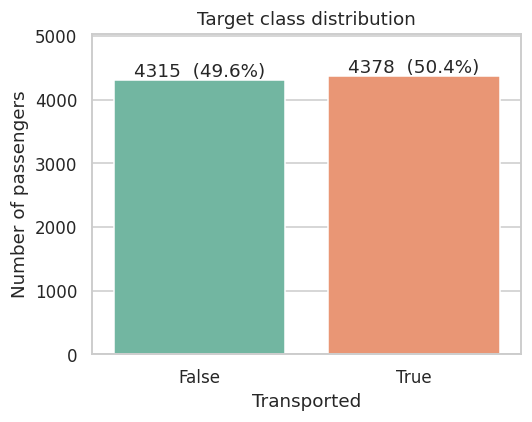

Positive class ratio: 0.5036


In [4]:
fig, ax = plt.subplots(figsize=(5, 4))
counts = train_raw["Transported"].value_counts().sort_index()
sns.barplot(x=counts.index.astype(str), y=counts.values, ax=ax,
            hue=counts.index.astype(str), legend=False, palette="Set2")
for i, v in enumerate(counts.values):
    ax.text(i, v + 40, f"{v}  ({v / counts.sum():.1%})", ha="center")
ax.set(xlabel="Transported", ylabel="Number of passengers",
       title="Target class distribution", ylim=(0, counts.max() * 1.15))
plt.tight_layout(); plt.show()

print(f"Positive class ratio: {train_raw['Transported'].mean():.4f}")

### 2.2 Missingness

Roughly 2% of the values are missing in almost every column, and the pattern is
close to uniform across the frame. This rules out a single systematic cause and
motivates a column-by-column imputation strategy rather than listwise deletion.

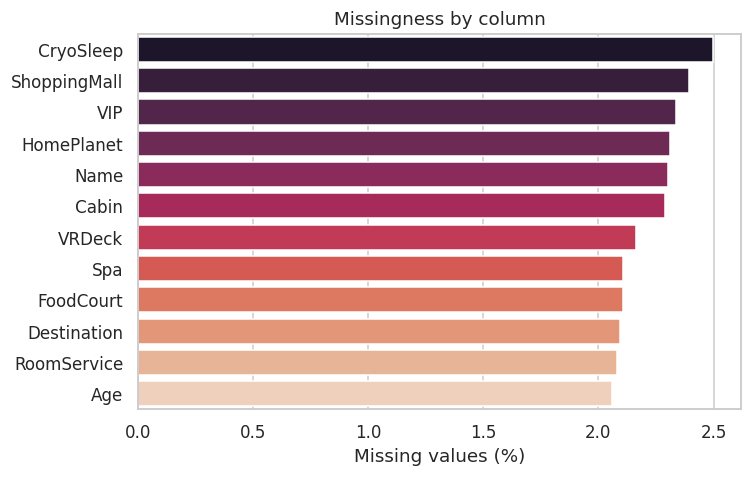

Rows with at least one missing value: 2087 (24.0%) — listwise deletion would discard a quarter of the data.


In [5]:
miss = (train_raw.isna().mean() * 100).sort_values(ascending=False)
miss = miss[miss > 0]

fig, ax = plt.subplots(figsize=(7, 4.5))
sns.barplot(x=miss.values, y=miss.index, ax=ax, hue=miss.index,
            legend=False, palette="rocket")
ax.set(xlabel="Missing values (%)", ylabel="", title="Missingness by column")
plt.tight_layout(); plt.show()

print(f"Rows with at least one missing value: "
      f"{train_raw.isna().any(axis=1).sum()} "
      f"({train_raw.isna().any(axis=1).mean():.1%}) — "
      f"listwise deletion would discard a quarter of the data.")

### 2.3 Categorical predictors

`CryoSleep` is by far the strongest single categorical signal: passengers in
suspended animation are transported at a much higher rate. `HomePlanet` also
separates the classes; `VIP` and `Destination` carry comparatively little
information.

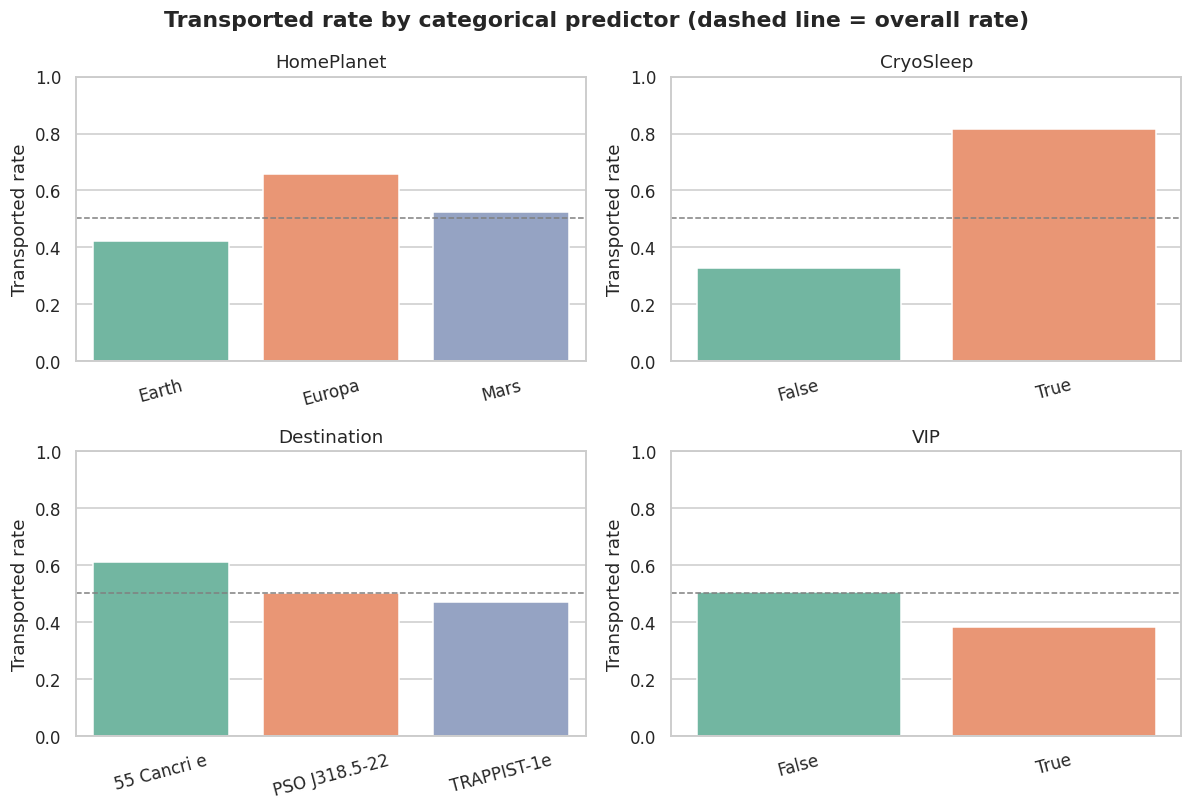

In [6]:
cat_cols = ["HomePlanet", "CryoSleep", "Destination", "VIP"]
fig, axes = plt.subplots(2, 2, figsize=(11, 7.5))
for ax, col in zip(axes.ravel(), cat_cols):
    rate = train_raw.groupby(col)["Transported"].agg(["mean", "size"])
    sns.barplot(x=rate.index.astype(str), y=rate["mean"], ax=ax,
                hue=rate.index.astype(str), legend=False, palette="Set2")
    ax.axhline(train_raw["Transported"].mean(), ls="--", c="grey", lw=1)
    ax.set(xlabel="", ylabel="Transported rate", title=col, ylim=(0, 1))
    ax.tick_params(axis="x", rotation=15)
fig.suptitle("Transported rate by categorical predictor "
             "(dashed line = overall rate)", fontweight="bold")
plt.tight_layout(); plt.show()

### 2.4 Spending behaviour

Expenditure is heavily right-skewed and zero-inflated, so it is shown on a
`log(1 + x)` scale. The pattern is unambiguous: passengers who spent nothing on
board were transported at a far higher rate. This is the single most
informative block of features in the dataset, as the ablation in notebook 2
confirms.

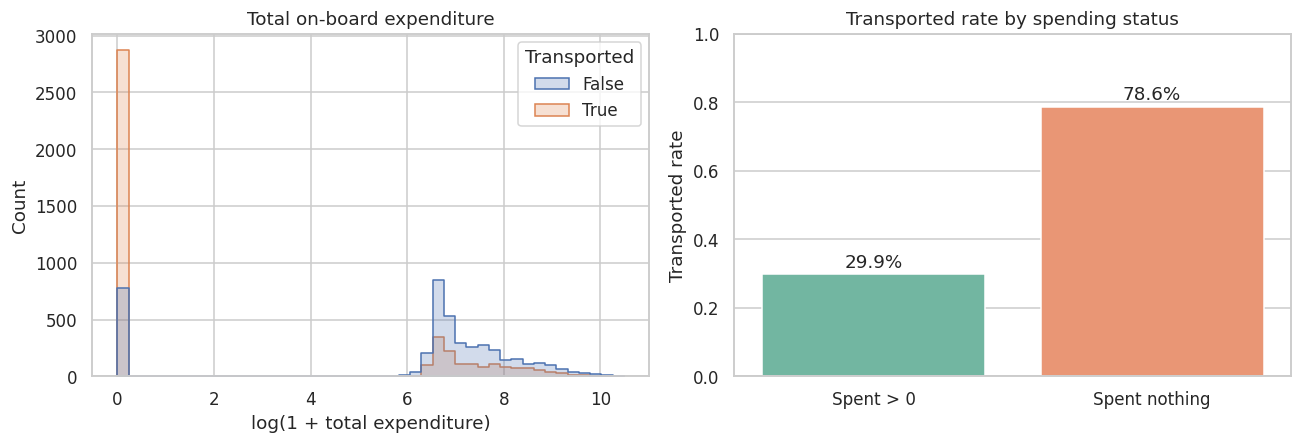

In [7]:
tmp = train_raw.copy()
tmp["TotalExpense"] = tmp[EXPENSE_COLS].sum(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
sns.histplot(data=tmp, x=np.log1p(tmp["TotalExpense"]), hue="Transported",
             bins=45, element="step", ax=axes[0])
axes[0].set(xlabel="log(1 + total expenditure)", ylabel="Count",
            title="Total on-board expenditure")

zero_rate = tmp.assign(NoSpend=(tmp["TotalExpense"] == 0)) \
               .groupby("NoSpend")["Transported"].mean()
sns.barplot(x=["Spent > 0", "Spent nothing"], y=zero_rate.values, ax=axes[1],
            hue=["Spent > 0", "Spent nothing"], legend=False, palette="Set2")
axes[1].set(ylabel="Transported rate", ylim=(0, 1),
            title="Transported rate by spending status")
for i, v in enumerate(zero_rate.values):
    axes[1].text(i, v + 0.02, f"{v:.1%}", ha="center")
plt.tight_layout(); plt.show()

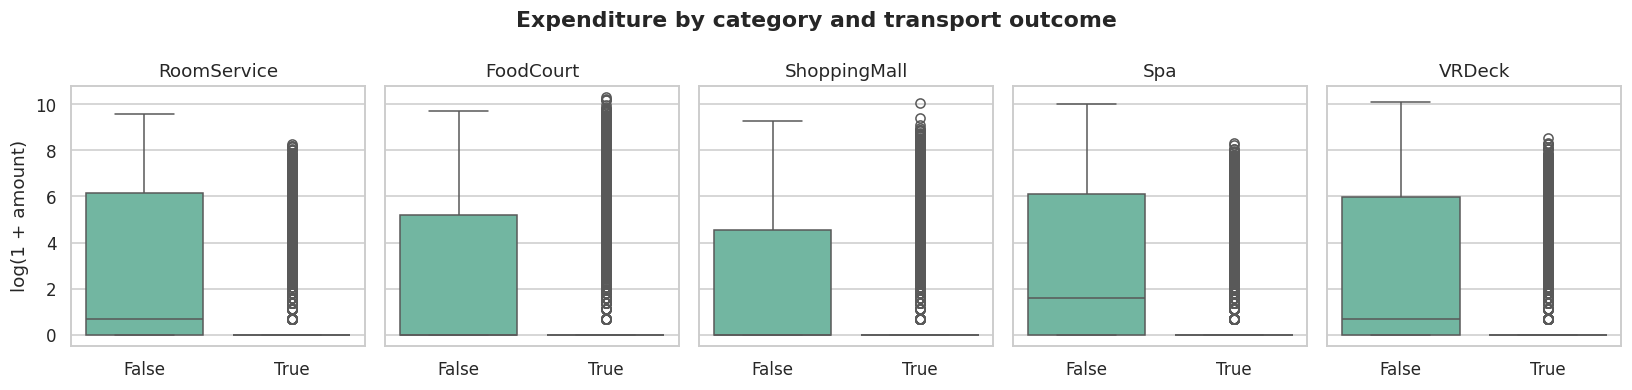

In [8]:
fig, axes = plt.subplots(1, 5, figsize=(15, 3.6), sharey=True)
for ax, col in zip(axes, EXPENSE_COLS):
    sns.boxplot(x=tmp["Transported"], y=np.log1p(tmp[col]), ax=ax,
                hue=tmp["Transported"], legend=False, palette="Set2")
    ax.set(xlabel="", ylabel="log(1 + amount)" if col == EXPENSE_COLS[0] else "",
           title=col)
fig.suptitle("Expenditure by category and transport outcome", fontweight="bold")
plt.tight_layout(); plt.show()

### 2.5 Age and cabin structure

Children under roughly 13 are transported noticeably more often. The cabin
identifier decomposes into deck, number and side; decks B and C stand out, and
the port/starboard split is informative despite being nearly balanced in
frequency.

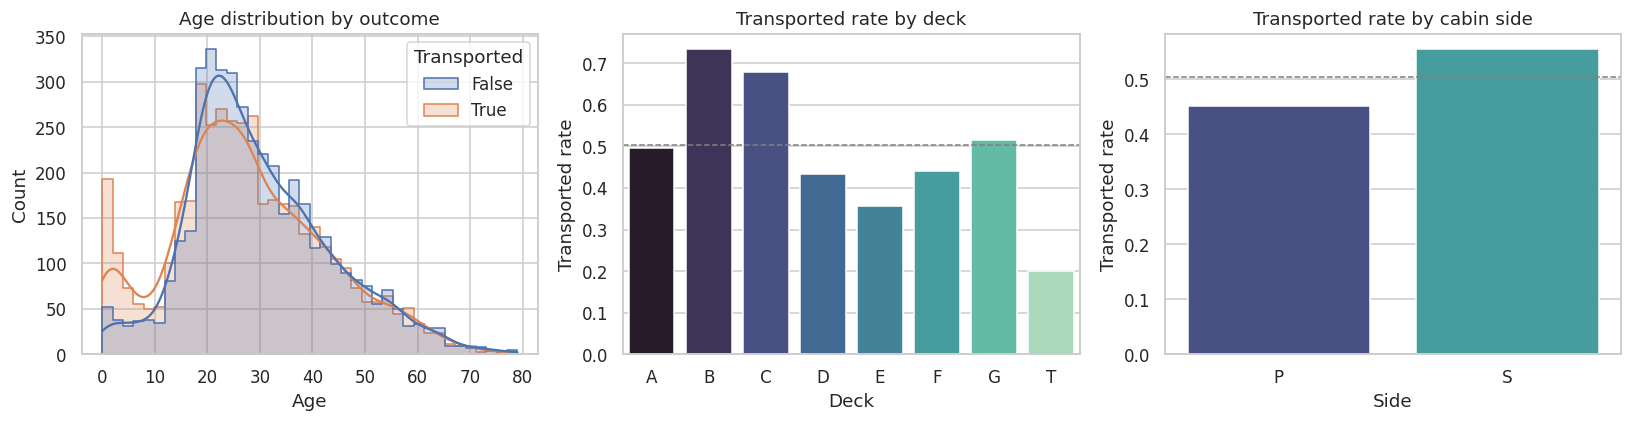

In [9]:
tmp[["Deck", "CabinNum", "Side"]] = tmp["Cabin"].str.split("/", expand=True)
tmp["CabinNum"] = pd.to_numeric(tmp["CabinNum"], errors="coerce")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(data=tmp, x="Age", hue="Transported", bins=40, kde=True,
             element="step", ax=axes[0])
axes[0].set(title="Age distribution by outcome")

deck_rate = tmp.dropna(subset=["Deck"]).groupby("Deck")["Transported"].mean()
sns.barplot(x=deck_rate.index, y=deck_rate.values, ax=axes[1],
            hue=deck_rate.index, legend=False, palette="mako")
axes[1].axhline(tmp["Transported"].mean(), ls="--", c="grey", lw=1)
axes[1].set(ylabel="Transported rate", title="Transported rate by deck")

side_rate = tmp.dropna(subset=["Side"]).groupby("Side")["Transported"].mean()
sns.barplot(x=side_rate.index, y=side_rate.values, ax=axes[2],
            hue=side_rate.index, legend=False, palette="mako")
axes[2].axhline(tmp["Transported"].mean(), ls="--", c="grey", lw=1)
axes[2].set(ylabel="Transported rate", title="Transported rate by cabin side")
plt.tight_layout(); plt.show()

### 2.6 Correlation among numeric predictors

No pair of numeric predictors exceeds |r| = 0.80, so multicollinearity is not a
concern for the linear baseline.

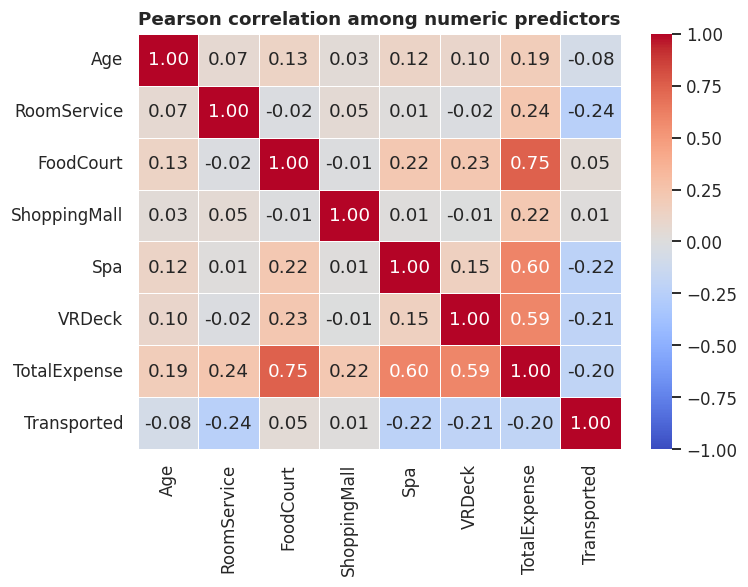

Largest absolute off-diagonal correlation: 0.745


In [10]:
num_cols = ["Age"] + EXPENSE_COLS + ["TotalExpense"]
corr = tmp[num_cols].assign(Transported=tmp["Transported"].astype(int)).corr()

fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            linewidths=0.5, vmin=-1, vmax=1, ax=ax)
ax.set_title("Pearson correlation among numeric predictors", fontweight="bold")
plt.tight_layout(); plt.show()

off_diag = corr.where(~np.eye(len(corr), dtype=bool)).abs().max().max()
print(f"Largest absolute off-diagonal correlation: {off_diag:.3f}")

## 3. Feature engineering pipeline

Everything below is wrapped in a single function so that the exact same
transformation is applied to both splits and the notebook can be re-run end to
end without hidden state.

**Imputation order.** Deterministic domain rules are applied first, because
they are exact rather than estimated:

| Rule | Justification |
|---|---|
| Any expenditure > 0 implies `CryoSleep = False` | Passengers in suspended animation cannot make purchases |
| `CryoSleep = True` implies every expense is 0 | Same constraint, applied in reverse |
| Age < 13 implies every expense is 0 | Minors have no on-board account |
| Passengers in one group share `HomePlanet` / `Destination` | Groups travel together |
| A cabin whose known occupants share one `CryoSleep` value propagates it | Cabins are assigned per travel party |

Only what remains after these rules is filled with group-conditional medians
and modes.

In [11]:
def build_features(train_raw: pd.DataFrame, test_raw: pd.DataFrame):
    """Return (X_train, y_train, X_test, test_ids) ready for modelling."""
    y = train_raw["Transported"].astype(int)
    n_train = len(train_raw)
    test_ids = test_raw["PassengerId"].copy()

    df = pd.concat([train_raw.drop(columns=["Transported"]), test_raw],
                   ignore_index=True)

    # --- 3.1 Group and family structure from the identifiers ---------------
    df["Group"] = df["PassengerId"].str.split("_").str[0]
    df["GroupSize"] = df["Group"].map(df["Group"].value_counts())
    df["Surname"] = df["Name"].str.split(" ").str[-1]
    df["FamilySize"] = df["Surname"].map(df["Surname"].value_counts()).fillna(1)
    df["Solo"] = (df["GroupSize"] == 1).astype(int)

    # --- 3.2 Deterministic domain rules -----------------------------------
    df["TotalExpense"] = df[EXPENSE_COLS].sum(axis=1, min_count=1)
    df.loc[(df["CryoSleep"].isna()) & (df["TotalExpense"] > 0), "CryoSleep"] = False
    for col in EXPENSE_COLS:
        df.loc[(df["CryoSleep"] == True) & (df[col].isna()), col] = 0.0
        df.loc[(df["Age"] < 13) & (df[col].isna()), col] = 0.0

    # --- 3.3 Propagation within groups and families -----------------------
    for col in ["HomePlanet", "Destination"]:
        by_group = df.dropna(subset=[col]).groupby("Group")[col].first()
        df[col] = df[col].fillna(df["Group"].map(by_group))
        by_surname = df.dropna(subset=[col]).groupby("Surname")[col].first()
        df[col] = df[col].fillna(df["Surname"].map(by_surname))

    by_group = df.dropna(subset=["Cabin"]).groupby("Group")["Cabin"].first()
    df["Cabin"] = df["Cabin"].fillna(df["Group"].map(by_group))

    n_unique = df.dropna(subset=["CryoSleep"]).groupby("Cabin")["CryoSleep"].nunique()
    homogeneous = n_unique[n_unique == 1].index
    cabin_map = (df[df["Cabin"].isin(homogeneous)]
                 .groupby("Cabin")["CryoSleep"].first())
    df["CryoSleep"] = df["CryoSleep"].fillna(df["Cabin"].map(cabin_map))
    df.loc[(df["CryoSleep"].isna()) & (df["TotalExpense"] == 0), "CryoSleep"] = True

    # --- 3.4 Cabin decomposition ------------------------------------------
    df[["Deck", "CabinNum", "Side"]] = df["Cabin"].str.split("/", expand=True)
    df["CabinNum"] = pd.to_numeric(df["CabinNum"], errors="coerce")
    df["ShipRegion"] = pd.cut(
        df["CabinNum"], bins=[-1, 300, 600, 900, 1200, 1500, 2100],
        labels=[f"R{i}" for i in range(1, 7)]).astype(object)

    # --- 3.5 Statistical fallbacks for whatever remains --------------------
    df["Age"] = df.groupby("HomePlanet")["Age"].transform(lambda s: s.fillna(s.median()))
    df["Age"] = df["Age"].fillna(df["Age"].median())
    for col in EXPENSE_COLS:
        df[col] = df.groupby(["HomePlanet", "CryoSleep"])[col].transform(
            lambda s: s.fillna(s.median()))
        df[col] = df[col].fillna(df[col].median())
    df["CryoSleep"] = df["CryoSleep"].fillna(False)
    df["VIP"] = df["VIP"].fillna(False)
    for col in ["HomePlanet", "Destination", "Deck", "Side", "ShipRegion"]:
        df[col] = df[col].fillna(df[col].mode()[0])
    df["CabinNum"] = df["CabinNum"].fillna(df["CabinNum"].median())

    # --- 3.6 Derived spending features ------------------------------------
    df["TotalExpense"] = df[EXPENSE_COLS].sum(axis=1)
    df["NoSpend"] = (df["TotalExpense"] == 0).astype(int)
    df["IsChild"] = (df["Age"] < 13).astype(int)
    df["NumServices"] = (df[EXPENSE_COLS] > 0).sum(axis=1)
    df["LuxurySpend"] = df["RoomService"] + df["Spa"] + df["VRDeck"]
    df["BasicSpend"] = df["FoodCourt"] + df["ShoppingMall"]
    for col in EXPENSE_COLS + ["TotalExpense", "LuxurySpend", "BasicSpend"]:
        df[f"log_{col}"] = np.log1p(df[col])

    df["CryoSleep"] = df["CryoSleep"].astype(int)
    df["VIP"] = df["VIP"].astype(int)

    # --- 3.7 Drop raw columns superseded by engineered ones ---------------
    drop_cols = (["PassengerId", "Name", "Surname", "Cabin", "Group",
                  "TotalExpense", "LuxurySpend", "BasicSpend"] + EXPENSE_COLS)
    df = df.drop(columns=drop_cols)

    df = pd.get_dummies(
        df, columns=["HomePlanet", "Destination", "Deck", "Side", "ShipRegion"],
        drop_first=True, dtype=int)

    X_train = df.iloc[:n_train].reset_index(drop=True)
    X_test = df.iloc[n_train:].reset_index(drop=True)
    return X_train, y, X_test, test_ids

In [12]:
X_train, y_train, X_test, test_ids = build_features(train_raw, test_raw)

print(f"Feature matrix (train) : {X_train.shape}")
print(f"Feature matrix (test)  : {X_test.shape}")
print(f"Remaining missing values: {X_train.isna().sum().sum()} (train), "
      f"{X_test.isna().sum().sum()} (test)")
print(f"Rows retained          : {len(X_train)} / {len(train_raw)} "
      f"({len(X_train) / len(train_raw):.1%})")
X_train.head()

Feature matrix (train) : (8693, 35)
Feature matrix (test)  : (4277, 35)
Remaining missing values: 0 (train), 0 (test)
Rows retained          : 8693 / 8693 (100.0%)


,CryoSleep,Age,VIP,GroupSize,FamilySize,Solo,CabinNum,NoSpend,IsChild,NumServices,...,Deck_E,Deck_F,Deck_G,Deck_T,Side_S,ShipRegion_R2,ShipRegion_R3,ShipRegion_R4,ShipRegion_R5,ShipRegion_R6
0,0,39.0,0,1,3.0,1,0.0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,24.0,0,1,4.0,1,0.0,0,0,5,...,0,1,0,0,1,0,0,0,0,0
2,0,58.0,1,2,7.0,0,0.0,0,0,4,...,0,0,0,0,1,0,0,0,0,0
3,0,33.0,0,2,7.0,0,0.0,0,0,4,...,0,0,0,0,1,0,0,0,0,0
4,0,16.0,0,1,9.0,1,1.0,0,0,5,...,0,1,0,0,1,0,0,0,0,0


### Feature inventory

The 35 predictors fall into four blocks. Notebook 2 measures the contribution
of each block by ablation.

In [13]:
blocks = {
    "Demographic / travel": ["CryoSleep", "Age", "VIP", "IsChild"],
    "Group & family": ["GroupSize", "FamilySize", "Solo"],
    "Spending": [c for c in X_train.columns if c.startswith("log_")]
                + ["NoSpend", "NumServices"],
    "Cabin / topography": ["CabinNum"]
                          + [c for c in X_train.columns
                             if c.startswith(("Deck_", "Side_", "ShipRegion_"))],
    "Origin / destination": [c for c in X_train.columns
                             if c.startswith(("HomePlanet_", "Destination_"))],
}
for name, cols in blocks.items():
    print(f"{name:22s} ({len(cols):2d}): {', '.join(cols)}")
print(f"\nTotal: {sum(len(v) for v in blocks.values())} features")

Demographic / travel   ( 4): CryoSleep, Age, VIP, IsChild
Group & family         ( 3): GroupSize, FamilySize, Solo
Spending               (10): log_RoomService, log_FoodCourt, log_ShoppingMall, log_Spa, log_VRDeck, log_TotalExpense, log_LuxurySpend, log_BasicSpend, NoSpend, NumServices
Cabin / topography     (14): CabinNum, Deck_B, Deck_C, Deck_D, Deck_E, Deck_F, Deck_G, Deck_T, Side_S, ShipRegion_R2, ShipRegion_R3, ShipRegion_R4, ShipRegion_R5, ShipRegion_R6
Origin / destination   ( 4): HomePlanet_Europa, HomePlanet_Mars, Destination_PSO J318.5-22, Destination_TRAPPIST-1e

Total: 35 features


## 4. Export

The modelling notebook reads only these three files.

In [14]:
X_train.to_csv(f"{OUT_DIR}/X_train.csv", index=False)
X_test.to_csv(f"{OUT_DIR}/X_test.csv", index=False)
pd.DataFrame({"Transported": y_train}).to_csv(f"{OUT_DIR}/y_train.csv", index=False)
test_ids.to_frame().to_csv(f"{OUT_DIR}/test_ids.csv", index=False)

print("Written: X_train.csv, X_test.csv, y_train.csv, test_ids.csv")

Written: X_train.csv, X_test.csv, y_train.csv, test_ids.csv
